# House Prices — So sánh ba cặp đặc trưng

Thử trên DummyRegressor, Ridge, Random Forest, Lasso, SVR với cùng 5 fold và tham số cố định. Delta âm nghĩa là RMSE giảm so với 79 cột của cùng mô hình.

## Tham số cố định

In [1]:
EXPERIMENT_NAME = "15-11-2026_5model_cap_dac_trung_phuc"
RANDOM_STATE = 42
N_SPLITS = 5

MODEL_PARAMS = {
    "DummyRegressor": {"strategy": "mean"},
    "Ridge": {"alpha": 1.0, "solver": "lsqr"},
    "Random Forest": {"n_estimators": 200, "min_samples_leaf": 2, "random_state": RANDOM_STATE},
    "Lasso": {"alpha": 0.001, "max_iter": 10000},
    "XGBoost": {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
                "random_state": RANDOM_STATE, "n_jobs": 2},
    "SVR": {"C": 10.0, "epsilon": 0.05, "gamma": "scale"},
}
MODEL_PARAMS.pop("XGBoost")

Out[1]: 
{'n_estimators': 200,
 'max_depth': 4,
 'learning_rate': 0.05,
 'random_state': 42,
 'n_jobs': 2}


## Import và kiểm tra kernel

In [2]:
from itertools import combinations
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor
from src.models import make_dummy, make_ridge, make_random_forest
from src.model import make_lasso, make_svr

## Dữ liệu và tạo đặc trưng

- `TotalSF` cộng diện tích tầng hầm, tầng 1 và tầng 2.
- `TotalBath` cộng phòng tắm đầy đủ ở phần trên mặt đất và tầng hầm. Mỗi nửa phòng tắm tính 0,5.
- `AgeAtSale` lấy năm bán trừ năm xây.

Các phép tính dùng dữ liệu của từng căn nhà. Pipeline điền thiếu, chuẩn hóa và mã hóa được fit trên phần train của từng fold.

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

formulas = {
    "TotalSF": "TotalBsmtSF + 1stFlrSF + 2ndFlrSF",
    "TotalBath": "FullBath + BsmtFullBath + 0.5 * (HalfBath + BsmtHalfBath)",
    "AgeAtSale": "YrSold - YearBuilt",
}
X_extra = X.assign(
    TotalSF=X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"],
    TotalBath=X["FullBath"] + X["BsmtFullBath"] + 0.5 * (X["HalfBath"] + X["BsmtHalfBath"]),
    AgeAtSale=X["YrSold"] - X["YearBuilt"],
)
assert X_extra.shape[1] == 82
display(X_extra[list(formulas)].describe().round(2))

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y, "fold": 0})
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold
baseline_dir = (project / "experiments" / "14-11-2026_6model_79_phuc"
                / "outputs" / "20261114_224507_500186")
baseline = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline[[ID, "fold"]])
np.testing.assert_allclose(y, baseline["ln_SalePrice"])

,TotalSF,TotalBath,AgeAtSale
count,1460.00,1460.00,1460.00
mean,2567.05,2.21,36.55
std,821.71,0.79,30.25
min,334.00,1.00,0.00
25%,2009.50,2.00,8.00
50%,2474.00,2.00,35.00
75%,3004.00,2.50,54.00
max,11752.00,6.00,136.00


## Huấn luyện và so sánh

In [4]:
factories = {
    "DummyRegressor": make_dummy, "Ridge": make_ridge,
    "Random Forest": make_random_forest, "Lasso": make_lasso, "SVR": make_svr,
}
metric_rows = []
warning_rows = []
fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
variants = {"79_goc": X}
feature_pairs = list(combinations(formulas, 2))
for pair in feature_pairs:
    variants[" + ".join(pair)] = X_extra.loc[:, [*X.columns, *pair]]

for model, factory in factories.items():
    for variant, features in variants.items():
        pipeline = make_pipeline(make_preprocessor(features), factory(**MODEL_PARAMS[model]))
        scores = []
        started = perf_counter()
        for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                fitted = clone(pipeline).fit(features.iloc[fit_idx], y.iloc[fit_idx])
                predicted = fitted.predict(features.iloc[valid_idx])
            predictions.loc[valid_idx, f"{model} | {variant}"] = predicted
            scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))
            for item in caught:
                warning_rows.append({"model": model, "variant": variant, "fold": fold,
                                     "category": item.category.__name__, "message": str(item.message)})
        metric_rows.append({
            "model": model, "variant": variant, "features": features.shape[1],
            **dict(zip(fold_columns, scores)),
            "rmse_log_mean": np.mean(scores), "rmse_log_std": np.std(scores, ddof=1),
            "elapsed_seconds": perf_counter() - started,
        })

results = pd.DataFrame(metric_rows).set_index(["model", "variant"])
reference = results.xs("79_goc", level="variant")
comparison = results[fold_columns].subtract(reference[fold_columns], axis="columns", level="model")
comparison["delta_mean"] = results["rmse_log_mean"].subtract(reference["rmse_log_mean"], level="model")
comparison["folds_improved"] = (comparison[fold_columns] < -1e-12).sum(axis=1)
display(results.join(comparison[["delta_mean", "folds_improved"]]).round(5))

features  ...  folds_improved
model          variant                          ...                
DummyRegressor 79_goc                       79  ...               0
               TotalSF + TotalBath          81  ...               0
               TotalSF + AgeAtSale          81  ...               0
               TotalBath + AgeAtSale        81  ...               0
Ridge          79_goc                       79  ...               0
               TotalSF + TotalBath          81  ...               1
               TotalSF + AgeAtSale          81  ...               3
               TotalBath + AgeAtSale        81  ...               3
Random Forest  79_goc                       79  ...               0
               TotalSF + TotalBath          81  ...               5
               TotalSF + AgeAtSale          81  ...               4
               TotalBath + AgeAtSale        81  ...               4
Lasso          79_goc                       79  ...               0
               TotalSF + TotalBath          81  ...               4
               TotalSF + AgeAtSale          81  ...               3
               TotalBath + AgeAtSale        81  ...               3
SVR            79_goc                       79  ...               0
               TotalSF + TotalBath          81  ...               5
               TotalSF + AgeAtSale          81  ...               4
               TotalBath + AgeAtSale        81  ...               4

[20 rows x 11 columns]

## Biểu đồ và nhận xét

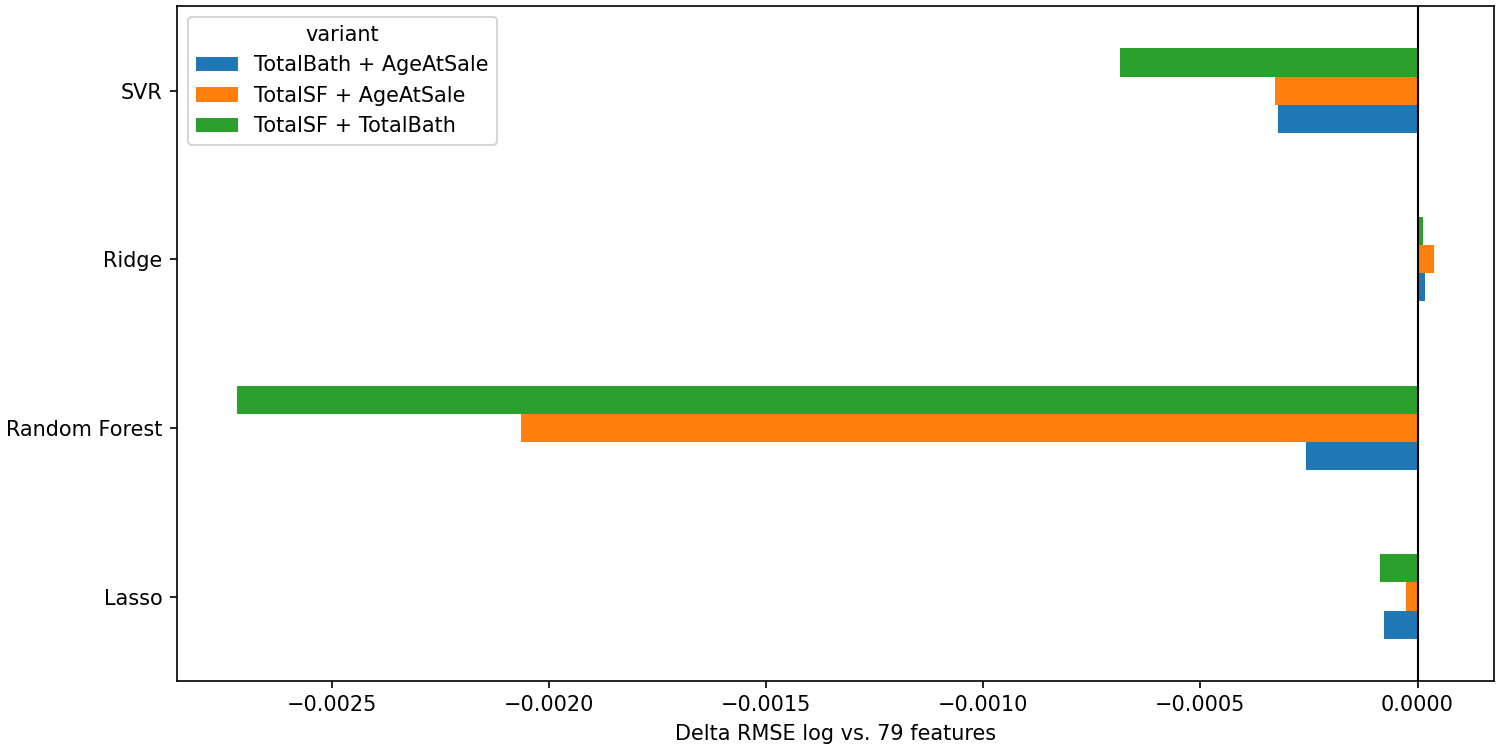

In [5]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
changes = comparison["delta_mean"].unstack().drop(columns="79_goc")
changes.drop(index="DummyRegressor").plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Delta RMSE log vs. 79 features", ylabel="")
plt.show()

## Lưu kết quả

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv")
comparison.to_csv(run_dir / "comparison_by_pair.csv")
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
pd.DataFrame(warning_rows, columns=["model", "variant", "fold", "category", "message"]).to_csv(
    run_dir / "validation_warnings.csv", index=False
)
config = {
    "dataset": "data/raw/train.csv", "target_transform": "natural log",
    "baseline": str(baseline_dir.relative_to(project)), "feature_formulas": formulas, "feature_pairs": feature_pairs,
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "model_params": MODEL_PARAMS,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "models_by_pair.png", dpi=150)
print(run_dir.relative_to(project))

experiments\15-11-2026_5model_cap_dac_trung_phuc\outputs\20261115_100204_335384
